# Parameter recovery and historical window selection

**Research question.** How much information do nested observed histories provide about the source dynamics?

Each family and seed contributes one long timeline; candidate windows are nested chronological prefixes. Source-exact model units are preserved and are not interpreted as decimal investable returns.

This recipe runs independently in the installed project environment. The default is a labelled smoke experiment; set `THESIS_PROFILE=pilot` before starting the kernel for the configured pilot counts. Source functions are reusable and directly linked below. Outputs report actual calculations, not assumed findings.

### Load calibration functions

Calibration truth is restricted to the researcher layer; the fitter sees observed values only.

**Inputs:** installed package.  
**Created / outputs:** configuration and functions.  
**Canonical implementation:** `annual.studies`.

In [1]:
# M5.RECOVERY.SETUP — Load calibration functions
# Inputs: installed package
# Created: configuration and functions
import os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from thesis_portfolio.annual.config import PublicSpec, load_run_config, oracle_state, project_root, stream
from thesis_portfolio.annual.simulation import generate_history, simulate_conditional_paths, oracle_continue
from thesis_portfolio.annual.estimation import fit_market_model
from thesis_portfolio.annual.portfolio import annual_moments, freeze_portfolios, evaluate_portfolios
from thesis_portfolio.optimization import equal_risk_contribution, markowitz, cvar, risk_contributions
from thesis_portfolio.annual.diagnostics import mathematical_backstops, residual_diagnostics, parameter_comparison, recurrence_report
from thesis_portfolio.annual.experiment import execution_profile, begin_run, save_run
from thesis_portfolio.annual import visualization as plots
from thesis_portfolio.annual.studies import recovery_study, history_selection, study_directory, save_study
root = project_root(os.environ.get('THESIS_PROJECT_ROOT'))
cfg = load_run_config(root/'configs/annual/pilot.yaml')


### Inspect source-exact fixtures

These values are transcribed from the supplied revision; source-derived annual pilots scale omega separately.

**Inputs:** source specifications.  
**Created / outputs:** parameter table.  
**Canonical implementation:** `annual.studies.source_fixture`.

In [2]:
# M5.RECOVERY.FIXTURES — Inspect source-exact fixtures
# Inputs: source specifications
# Created: parameter table
from thesis_portfolio.annual.studies import source_fixture
display(pd.DataFrame([{ 'family':f,'omega':source_fixture(f).omega[0], 'alpha':source_fixture(f).alpha[0], 'beta':source_fixture(f).beta[0], 'gamma':source_fixture(f).gamma[0], 'long_run_variance':source_fixture(f).long_run_variance[0]} for f in ('garch','gjr')]))


,family,omega,alpha,beta,gamma,long_run_variance
0,garch,0.0001,0.20,0.5,0.00,0.000333
1,gjr,0.0200,0.03,0.9,0.06,0.500000


### Fit all prespecified nested prefixes

Failed fits stay in the table. No reseeding seeks a favorable parameter estimate.

**Inputs:** length grid, fixed calibration seed.  
**Created / outputs:** recovery.  
**Canonical implementation:** `annual.studies.recovery_study`.

In [3]:
# M5.RECOVERY.RUN — Fit all prespecified nested prefixes
# Inputs: length grid, fixed calibration seed
# Created: recovery
lengths = (300,600,1000,1200)
recovery = recovery_study(lengths, seeds=(cfg['seed'],), spec_options=cfg['fit'])
display(recovery)


,family,seed,observations,success,units,mu,omega,alpha,beta,gamma,...,true_gamma,error_gamma,true_persistence,error_persistence,true_long_run_variance,error_long_run_variance,volatility_normalized_rmse,next_variance_error,boundary,standard_errors
0,garch,20261127,300,True,"source-exact model units, not investable decim...",-0.000944,0.000121,0.125577,0.480552,0.000000,...,0.00,0.000000,0.70,-0.093871,0.000333,-0.000026,0.055834,-0.000107,False,not reported: boundary-aware inference deferred
1,garch,20261127,600,True,"source-exact model units, not investable decim...",-0.000818,0.000125,0.245695,0.402562,0.000000,...,0.00,0.000000,0.70,-0.051743,0.000333,0.000022,0.034200,0.000030,False,not reported: boundary-aware inference deferred
2,garch,20261127,1000,True,"source-exact model units, not investable decim...",-0.000414,0.000118,0.231940,0.429537,0.000000,...,0.00,0.000000,0.70,-0.038522,0.000333,0.000015,0.023578,0.000010,False,not reported: boundary-aware inference deferred
3,garch,20261127,1200,True,"source-exact model units, not investable decim...",-0.000295,0.000122,0.228262,0.413556,0.000000,...,0.00,0.000000,0.70,-0.058182,0.000333,0.000008,0.022239,0.000001,False,not reported: boundary-aware inference deferred
4,gjr,20261127,300,True,"source-exact model units, not investable decim...",0.066589,0.022591,0.063811,0.868473,0.000000,...,0.06,-0.060000,0.96,-0.027717,0.500000,-0.166394,0.069317,-0.057848,True,not reported: boundary-aware inference deferred
5,gjr,20261127,600,True,"source-exact model units, not investable decim...",0.063031,0.019659,0.031523,0.906045,0.015858,...,0.06,-0.044142,0.96,-0.014503,0.500000,-0.139307,0.049971,-0.101732,False,not reported: boundary-aware inference deferred
6,gjr,20261127,1000,True,"source-exact model units, not investable decim...",0.049855,0.012360,0.014406,0.928863,0.056840,...,0.06,-0.003160,0.96,0.011689,0.500000,-0.063431,0.030735,0.051060,False,not reported: boundary-aware inference deferred
7,gjr,20261127,1200,True,"source-exact model units, not investable decim...",0.041642,0.013543,0.011999,0.927140,0.059226,...,0.06,-0.000774,0.96,0.008751,0.500000,-0.066594,0.031073,-0.004127,False,not reported: boundary-aware inference deferred


### Inspect persistence and volatility error

A single seed illustrates finite-history uncertainty and cannot establish reliable parameter recovery on its own.

**Inputs:** recovery table.  
**Created / outputs:** selected error columns.  
**Canonical implementation:** `annual.diagnostics.parameter_comparison`.

In [4]:
# M5.RECOVERY.ERRORS — Inspect persistence and volatility error
# Inputs: recovery table
# Created: selected error columns
display(recovery[['family','observations','success','error_persistence','error_long_run_variance','volatility_normalized_rmse','next_variance_error']])


,family,observations,success,error_persistence,error_long_run_variance,volatility_normalized_rmse,next_variance_error
0,garch,300,True,-0.093871,-0.000026,0.055834,-0.000107
1,garch,600,True,-0.051743,0.000022,0.034200,0.000030
2,garch,1000,True,-0.038522,0.000015,0.023578,0.000010
3,garch,1200,True,-0.058182,0.000008,0.022239,0.000001
4,gjr,300,True,-0.027717,-0.166394,0.069317,-0.057848
5,gjr,600,True,-0.014503,-0.139307,0.049971,-0.101732
6,gjr,1000,True,0.011689,-0.063431,0.030735,0.051060
7,gjr,1200,True,0.008751,-0.066594,0.031073,-0.004127


### Plot recovery across historical lengths

Errors need not decrease monotonically for every prefix. Interpret the entire table, including boundary estimates.

**Inputs:** recovery.  
**Created / outputs:** recovery figure.  
**Canonical implementation:** `annual.visualization.recovery_figure`.

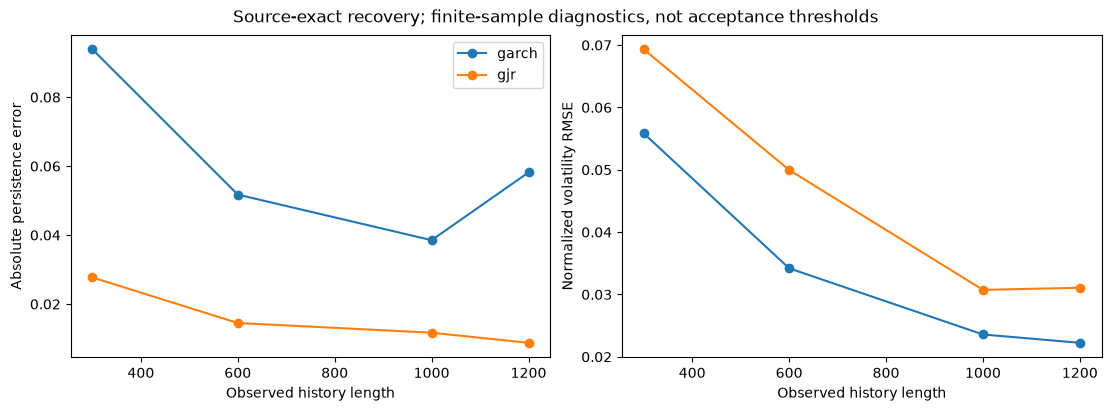

In [5]:
# M5.RECOVERY.PLOT — Plot recovery across historical lengths
# Inputs: recovery
# Created: recovery figure
recovery_plot = plots.recovery_figure(recovery)
plt.show()


### Record selection status honestly

No numerical adequacy criteria were approved. Retain 1000 as a labelled integration reference rather than claiming a calibrated minimum.

**Inputs:** recovery, configured reference.  
**Created / outputs:** selection.  
**Canonical implementation:** `annual.studies.history_selection`.

In [6]:
# M5.RECOVERY.SELECTION — Record selection status honestly
# Inputs: recovery, configured reference
# Created: selection
selection = history_selection(recovery, cfg['history']['reference'])
display(selection)


{'selected_n': 1000,
 'status': 'provisional_reference_not_calibrated',
 'reason': 'Recovery adequacy criteria require researcher review; no automatic success claim.',
 'fits': 8,
 'failed_fits': 0}

### Save calibration evidence separately

Production histories use different named streams and are never prefixes of these calibration histories.

**Inputs:** recovery, selection, figure.  
**Created / outputs:** calibration run.  
**Canonical implementation:** `annual.studies.save_study`.

In [7]:
# M5.RECOVERY.SAVE — Save calibration evidence separately
# Inputs: recovery, selection, figure
# Created: calibration run
path = study_directory(root,'recovery')
save_study(path, {'recovery':recovery}, {'selection':selection,'seeds':[cfg['seed']],'lengths':lengths})
recovery_plot.savefig(path/'recovery.png',dpi=150,bbox_inches='tight')
print(path)


/Users/morty/Documents/ChatGPT/Thesis Under Prof. Rubtsov/results/m05-recovery-20261127T163446-2105abe7
